# Certificado gauge para factorización rango uno

## tl;dr

En 120 réplicas, el residual gauge máximo fue **2.538e-17**, la predicción cambió como máximo **1.534e-15** y la fijación de gauge redujo la inestabilidad paramétrica al menos **100.000000%**. El punto regular tuvo nulidad 1; el caso degenerado no fue confundido con una única simetría de escala.

## Contexto y métodos

Modelo: `Y = u vᵀ + epsilon`, con ruido gaussiano iid y matriz completamente observada. La órbita `(u,v) ~ (c u,v/c)` conserva la distribución. Comparamos Jacobiano analítico contra diferencias centrales y factores sin fijar contra una sección SVD balanceada.

### Supuestos clave

Factores no nulos para el resultado regular; rango uno; varianza conocida; umbral espectral de precisión de máquina. La nulidad es un diagnóstico local, no prueba automática de simetría global.

## Datos

Resultados sintéticos generados desde `config.json`; cada fila cruda conserva su semilla.

In [1]:
import csv, json
from pathlib import Path
import numpy as np
from src.gauge import analytic_jacobian, fisher_information, gauge_tangent, spectral_certificate

root = Path.cwd()
config = json.loads((root / 'config.json').read_text())
results = json.loads((root / 'benchmarks/results.json').read_text())
with (root / 'benchmarks/summary.csv').open() as stream:
    summary = list(csv.DictReader(stream))
assert len(summary) == 6 and all(results['gates'].values())
{'configurations': len(summary), 'raw_rows': results['design']['rows'], 'gates': results['gates']}

Out[0]: 
{'configurations': 6,
 'raw_rows': 120,
 'gates': {'gauge_residual': True,
  'prediction_invariance': True,
  'instability_reduction': True,
  'regular_nullity_exactly_one': True,
  'degenerate_case_rejected': True}}


## Resultados

### 1. Verificación local independiente

In [2]:
u = np.array([1.0, -0.5, 0.25])
v = np.array([0.8, -0.3])
jacobian = analytic_jacobian(u, v)
certificate = spectral_certificate(fisher_information(jacobian, 0.05))
residual = np.linalg.norm(jacobian @ gauge_tangent(u, v)) / np.linalg.norm(gauge_tangent(u, v))
assert certificate.nullity == 1 and residual < 1e-12
{'nullity': certificate.nullity, 'rank': certificate.rank, 'gauge_residual': residual}

Out[0]: {'nullity': 1, 'rank': 4, 'gauge_residual': np.float64(0.0)}


### 2. Tabla exacta por configuración

In [3]:
selected = [{
    'shape': f"{row['m']}x{row['n']}",
    'sigma': float(row['noise_std']),
    'analytic_ms': round(float(row['median_analytic_ms']), 4),
    'finite_difference_ms': round(float(row['median_finite_difference_ms']), 4),
    'speedup': round(float(row['median_speedup']), 2),
    'nullity': int(row['nullity_mode'])
} for row in summary]
selected

Out[0]: 
[{'shape': '8x6',
  'sigma': 0.01,
  'analytic_ms': 0.1109,
  'finite_difference_ms': 0.8103,
  'speedup': 7.29,
  'nullity': 1},
 {'shape': '8x6',
  'sigma': 0.05,
  'analytic_ms': 0.1119,
  'finite_difference_ms': 0.7262,
  'speedup': 6.57,
  'nullity': 1},
 {'shape': '32x24',
  'sigma': 0.01,
  'analytic_ms': 0.4763,
  'finite_difference_ms': 3.4714,
  'speedup': 7.06,
  'nullity': 1},
 {'shape': '32x24',
  'sigma': 0.05,
  'analytic_ms': 0.4427,
  'finite_difference_ms': 3.1966,
  'speedup': 6.94,
  'nullity': 1},
 {'shape': '96x64',
  'sigma': 0.01,
  'analytic_ms': 1.9122,
  'finite_difference_ms': 12.5931,
  'speedup': 6.41,
  'nullity': 1},
 {'shape': '96x64',
  'sigma': 0.05,
  'analytic_ms': 1.8335,
  'finite_difference_ms': 12.4276,
  'speedup': 6.77,
  'nullity': 1}]


### 3. Figura reproducida por el benchmark


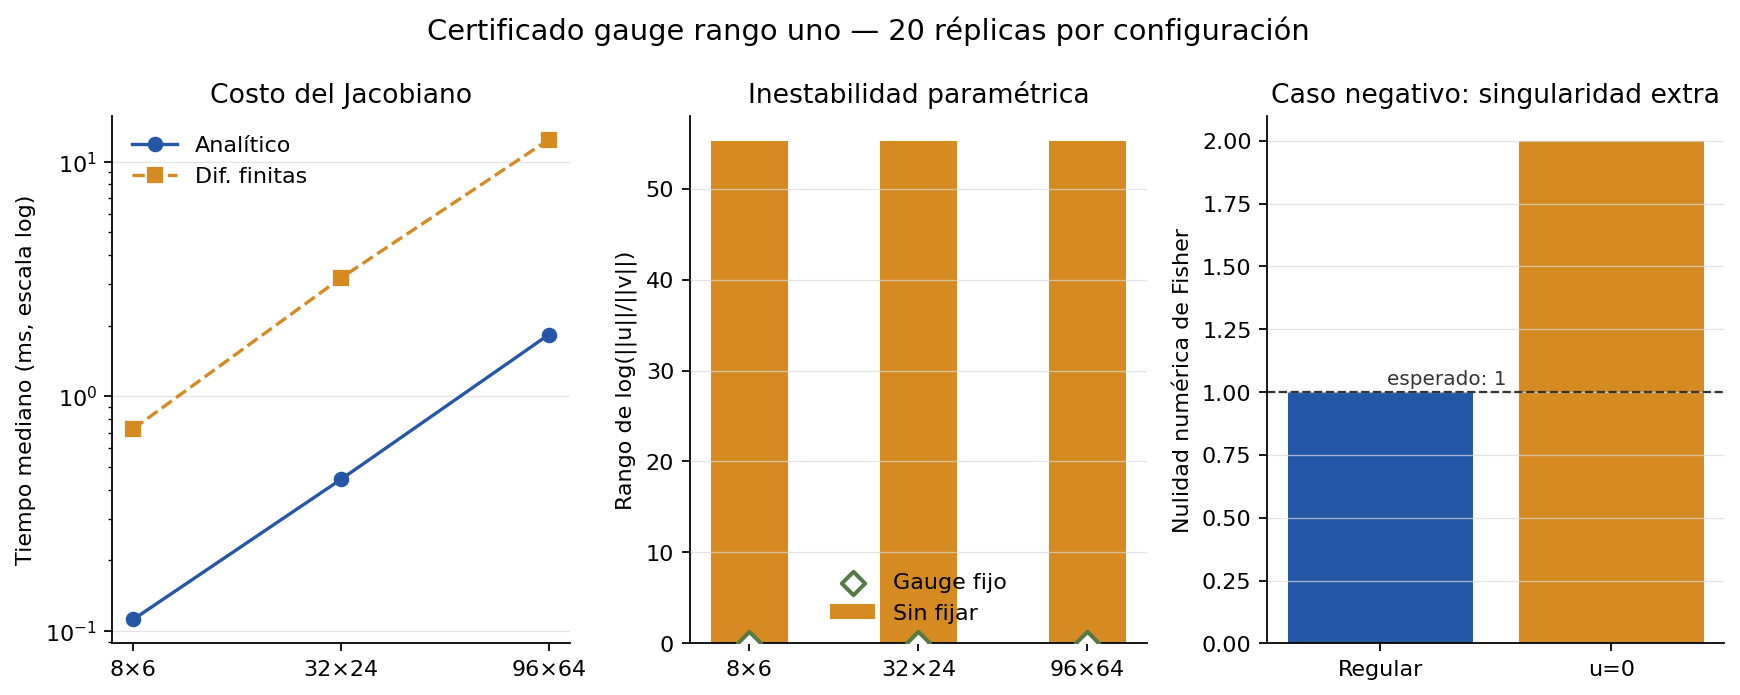

In [4]:
from base64 import b64encode
from IPython.display import HTML, display
figure = root / 'benchmarks/gauge-certificate.png'
assert figure.stat().st_size > 10_000
encoded = b64encode(figure.read_bytes()).decode('ascii')
display(HTML(f'<img src="data:image/png;base64,{encoded}" alt="Tres paneles: costo del Jacobiano, inestabilidad de escala y nulidad regular frente a degenerada">'))

## Conclusiones

El certificado responde afirmativamente solo en el caso acotado: reconoce la dirección de escala conocida y la sección balanceada elimina la arbitrariedad sin alterar la predicción. La nulidad mayor del caso `u=0` es la ablation negativa esencial: una Fisher singular por sí sola no identifica qué simetría o degeneración la produjo. Siguiente prueba: acción `GL(r)` para rango mayor.